# GROUP34_CENG313 — Assignment 1: EDA ve Baseline

**Hacı Kerem Mermer — 23118080769**; **Necdet Atakan Aydın — 24118080793**.

## 1. Problem, hedef ve metrik
Bir Reddit yorumunun verilen topluluk kuralını ihlal etme olasılığını tahmin ediyoruz.
`rule_violation=1` ihlal, `0` ihlal yoktur. Çıktı 0–1 arası olasılıktır.
[Yarışma](https://www.kaggle.com/competitions/jigsaw-agile-community-rules/overview/abstract) column-averaged AUC kullanır; yerel karşılığımız kuralların ROC-AUC değerlerinin eşit ağırlıklı ortalamasıdır. Tek sınıflı kurallar tanımsız bırakılır. Genel ROC-AUC, accuracy ve F1 ek ölçütlerdir.

Bu çalışma resmi Kaggle gönderimi içermez. Etiketli gizli test verisi bulunmadığı için %20 held-out değerlendirmesi sunulur. Önceki baseline çalışması tüm veri üzerinde keşif içerdiğinden bu yeni ayrımın tarihsel olarak hiç görülmemiş bir test olduğu iddia edilmez.

**Çalıştırma:** Yerelde ZIP'i açın, verileri Kaggle'dan indirip `data/` altına koyun, `pip install -r requirements.txt` ardından Jupyter ile bu dosyayı açın. Colab'da önce bu notebook'u açın; aşağıdaki hücre isterse teslim ZIP'ini yükleyin. Veri dosyaları repoda bulunmaz.

In [1]:
from pathlib import Path
import sys
# Accept both the course package and GitHub's Download ZIP archive.
if not Path('src/data.py').is_file():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Open this notebook from the project root, next to src/.')
    from zipfile import ZipFile
    uploaded = files.upload()
    archives = [name for name in uploaded if name.lower().endswith('.zip')]
    if len(archives) != 1:
        raise ValueError('Upload one project ZIP containing src/ and requirements.txt.')
    allowed = ['requirements.txt', 'src/__init__.py', 'src/data.py',
               'src/models.py', 'src/utils.py', 'src/eda.py']
    with ZipFile(archives[0]) as archive:
        members = {}
        for name in allowed:
            matches = [member for member in archive.namelist()
                       if member == name or member.endswith('/' + name)]
            if len(matches) != 1:
                raise ValueError(f'Missing or ambiguous source file in ZIP: {name}')
            members[name] = matches[0]
        for name, member in members.items():
            target = Path(name)
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(archive.read(member))
    del uploaded


In [2]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data import load_data, make_text, split_data, heldout_split
from src.models import build_models, compare_models
from src.utils import evaluate_model
from src.eda import plot_target, plot_rules, plot_subreddits, plot_lengths, rule_summary

if not Path('data/train.csv').is_file() and 'google.colab' in sys.modules:
    from google.colab import files
    uploaded = files.upload()
    required = ['train.csv', 'test.csv', 'sample_submission.csv']
    if not all(name in uploaded for name in required):
        raise ValueError('Üç CSV dosyasını birlikte yükleyin.')
    Path('data').mkdir(exist_ok=True)
    for name in required:
        Path('data', name).write_bytes(uploaded[name])
    del uploaded
train, test = load_data('data')
print('Eğitim boyutu:', train.shape, '| Örnek test boyutu:', test.shape)
assert train['rule_violation'].isin([0,1]).all()
development, heldout, removed = heldout_split(train)
print('Geliştirme:', len(development), '| Held-out:', len(heldout), '| Eğitimden çıkarılan örtüşen yorum:', removed)
assert set(development.body.str.lower().str.strip()).isdisjoint(heldout.body.str.lower().str.strip())


Eğitim boyutu: (2029, 9) | Örnek test boyutu: (10, 8)
Geliştirme: 1516 | Held-out: 406 | Eğitimden çıkarılan örtüşen yorum: 107


## 2. Veri özeti
%20 test ayrımı `random_state=42`, `stratify=y` ile sabitlenir. Test yorumuyla eşleşen normalize edilmiş yorumlar geliştirmeden çıkarılır; test değiştirilmez. Böylece test oranı yaklaşık %20 kalır ve yorum sızıntısı engellenir. Aşağıdaki EDA yalnızca geliştirme verisini kullanır. Satır metinlerini yazdırmak yerine toplulaştırılmış istatistikler raporlanır.

In [4]:
overview = pd.DataFrame({'tip': development.dtypes.astype(str),
                         'eksik': development.isna().sum(),
                         'benzersiz': development.nunique()})
display(overview)
display(development.describe(include='all').T)
print('Tam tekrar:', development.duplicated().sum())
print('Yorum tekrarı:', development.body.str.lower().str.strip().duplicated().sum())
lengths = development.body.fillna('').str.len()
display(lengths.describe().to_frame('yorum_karakter_sayisi'))


Tam tekrar: 0
Yorum tekrarı: 36


,tip,eksik,benzersiz
row_id,int64,0,1516
body,str,0,1481
rule,str,0,2
subreddit,str,0,98
positive_example_1,str,0,441
positive_example_2,str,0,448
negative_example_1,str,0,447
negative_example_2,str,0,446
rule_violation,int64,0,2


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
row_id,1516.0,NaN,NaN,NaN,1000.565963,585.401761,0.0,495.5,1001.0,1497.5,2028.0
body,1516,1481,49 http://MySexFind.com - find girl for sex no...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rule,1516,2,No legal advice: Do not offer or request legal...,812,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subreddit,1516,98,legaladvice,174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positive_example_1,1516,441,If anybody wants free case to open. Here is pr...,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
positive_example_2,1516,448,If anybody wants free case to open. Here is pr...,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
negative_example_1,1516,447,Oh that's interesting. You should check out my...,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
negative_example_2,1516,446,[So great! Thanks for sharing.](http://www.che...,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rule_violation,1516.0,NaN,NaN,NaN,0.519789,0.499773,0.0,0.0,1.0,1.0,1.0


,yorum_karakter_sayisi
count,1516.000000
mean,180.484169
std,113.443196
min,51.000000
25%,89.000000
50%,145.000000
75%,245.000000
max,499.000000


**Yorum:** `row_id` sayısal olsa da kimliktir; modele verilmez. `body`, `rule`, subreddit ve örnekler metindir. Tam satır tekrarı ile farklı kural/örnekler altında yinelenen yorum aynı şey değildir. Tekrarlanan yorumlar otomatik silinmez; değerlendirme ayrımlarında grup olarak tutulur. Eksiklik sayıları hangi sütunlarda doldurma gerektiğini gösterir.

## 3. Keşifsel veri analizi

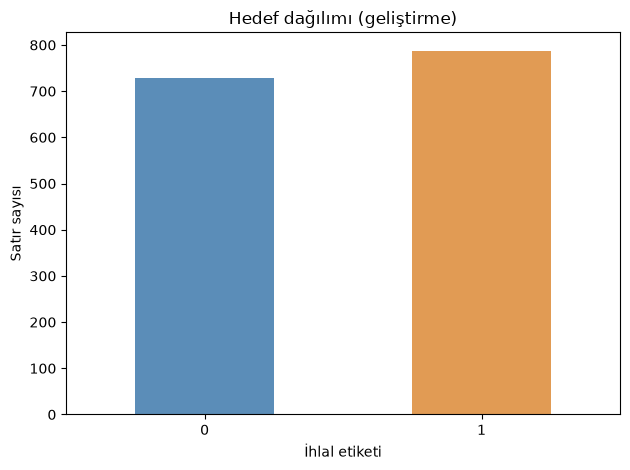

**Yorum:** Geliştirme bölümünde ihlal oranı %52.0. Sınıflar birbirine yakın olduğundan yalnızca accuracy yerine olasılık sıralamasını ölçen AUC esas alınır; Dummy model referans sağlar.

In [5]:
fig = plot_target(development)
plt.show()
counts = development.rule_violation.value_counts()
display(Markdown(f"**Yorum:** Geliştirme bölümünde ihlal oranı %{development.rule_violation.mean()*100:.1f}. Sınıflar birbirine yakın olduğundan yalnızca accuracy yerine olasılık sıralamasını ölçen AUC esas alınır; Dummy model referans sağlar."))

,satir,ihlal_orani
rule,,
"No Advertising: Spam, referral links, unsolicited advertising, and promotional content are not allowed.",704,0.447443
No legal advice: Do not offer or request legal advice.,812,0.582512


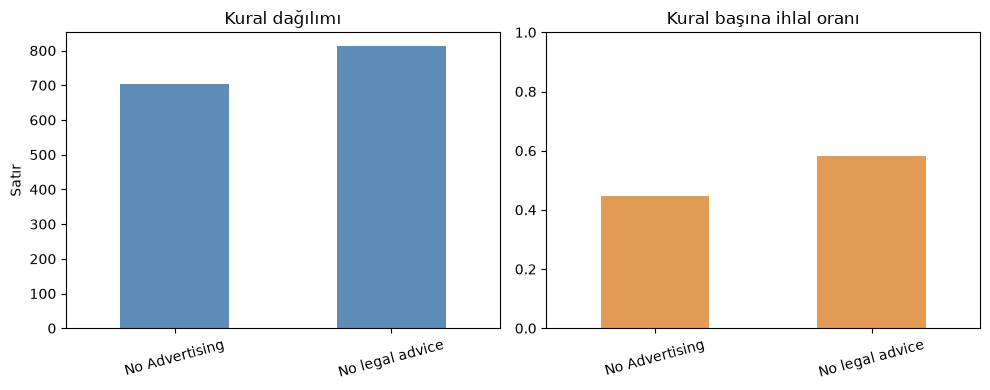

In [6]:
display(rule_summary(development))
fig = plot_rules(development)
plt.show()

**Yorum:** Veri iki kuralla sınırlıdır; kural sayıları ve ihlal oranları ayrı gösterilmiştir. Kural başına taban oran farklılığı, tek bir genel skorun bazı farkları gizleyebileceğini gösterir. Kural başına AUC raporlanır. Bu bölme görülmemiş bir kurala genellemeyi ölçmez.

Geliştirme bölümündeki subreddit sayısı: 98


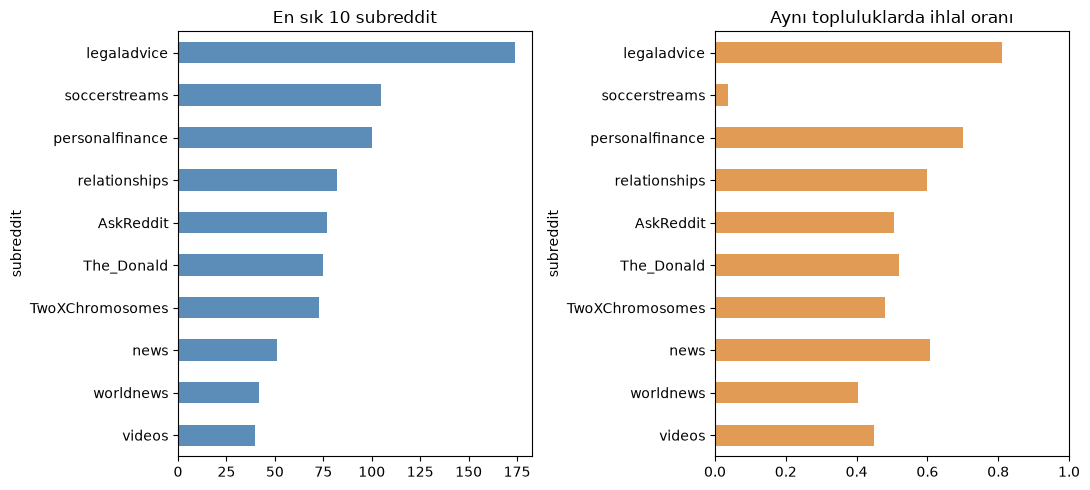

In [7]:
fig = plot_subreddits(development)
plt.show()
print('Geliştirme bölümündeki subreddit sayısı:', development.subreddit.nunique())

**Yorum:** Yalnızca en sık 10 topluluk gösterilir. İhlal oranlarındaki farklar topluluk bağlamının etkili olabileceğini düşündürür; küçük örnekli toplulukların oranları belirsizdir ve nedensellik göstermez. İlk baseline subreddit'i kullanmaz; bu özellik ikinci ödevde ayrı doğrulamayla değerlendirilebilir.

IQR üst sınırı: 479.0 | Sınır dışı yorum sayısı: 15


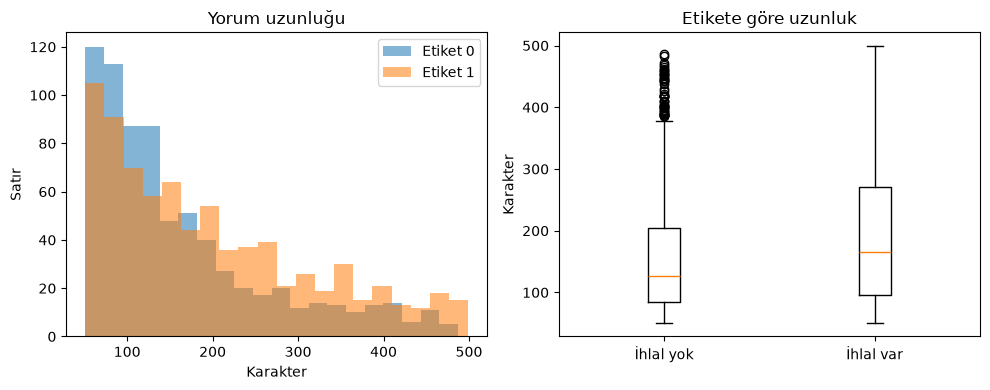

,count,median,mean,min,max
rule_violation,,,,,
0,728,126.0,162.306319,51,487
1,788,165.0,197.277919,51,499


In [8]:
fig = plot_lengths(development)
plt.show()
q1, q3 = lengths.quantile([.25,.75])
upper = q3 + 1.5*(q3-q1)
print('IQR üst sınırı:', upper, '| Sınır dışı yorum sayısı:', int(((lengths < q1-1.5*(q3-q1)) | (lengths > upper)).sum()))
display(development.assign(uzunluk=lengths).groupby('rule_violation').uzunluk.agg(['count','median','mean','min','max']))

**Yorum:** Histogram ve kutu grafiği, uzunluğun etiketle ilişkisini ve kuyrukları incelemek içindir. Dağılımlar örtüştüğünden uzunluk tek başına güvenilir karar kuralı değildir. IQR sınırı istatistiksel bir işarettir; uzun yorumun hatalı kayıt olduğu anlamına gelmez. Metinleri kesmek veya uzun yorumları çıkarmak anlam kaybına yol açabileceğinden bu baseline'da uygulanmaz.

## 4. Ön işleme kararları
- Eksik `body` ve `rule` metinleri boş dizeye çevrilir; sayısal imputasyon gerekmez.
- Kural ve yorum `RULE: ... COMMENT: ...` biçiminde birleştirilir; aynı yorumun farklı kurallarda farklı etiket alabilmesi korunur.
- TF-IDF kendi küçük harfe çevirme/tokenizasyonunu yapar. Elle stopword temizleme ve kök bulma uygulanmaz; olumsuzluk ve bağlam kaybolabilir.
- Seyrek metin vektörlerinde ek standartlaştırma uygulanmaz; TF-IDF varsayılan L2 normalizasyonu kullanılır.
- `row_id`, subreddit ve örnek yorumlar modele eklenmez. Kimlik sızıntısından ve başlangıç modelinin gereksiz karmaşıklığından kaçınılır.
- Vektörleştirici pipeline içinde yalnızca eğitim bölümünde fit edilir. Grup oluşturma dışında bütün veriye önceden fit yapılmaz.

## 5. Baseline ve geliştirme doğrulaması
Dummy, kelime TF-IDF + Logistic Regression ve karakter TF-IDF + Logistic Regression karşılaştırılır. Parametreler `src/models.py` içindedir. Model seçimi held-out dışındaki geliştirme verisinde 7, 21 ve 42 tohumlu gruplu bölmelerle yapılır; bölmelerin skorları bağımsız deneyler olarak yorumlanmaz.

In [9]:
results, summary, selected = compare_models(development)
display(results.round(4))
display(summary.round(4))
print('Geliştirme AUC ölçütüne göre seçilen model:', selected)
Path('submissions').mkdir(exist_ok=True)
results.to_csv('submissions/development_results.csv',index=False)


Geliştirme AUC ölçütüne göre seçilen model: char_logistic


,model,seed,roc_auc,mean_rule_auc,accuracy,f1
0,dummy,7,0.5000,0.5000,0.5017,0.6682
1,tfidf_logistic,7,0.7611,0.7479,0.7090,0.7387
2,char_logistic,7,0.7719,0.7660,0.6990,0.7337
3,dummy,21,0.5000,0.5000,0.5116,0.6769
4,tfidf_logistic,21,0.7788,0.7802,0.7294,0.7670
5,char_logistic,21,0.8060,0.8112,0.7261,0.7649
6,dummy,42,0.5000,0.5000,0.5485,0.7084
7,tfidf_logistic,42,0.7324,0.7548,0.6856,0.7299
8,char_logistic,42,0.7488,0.7647,0.6756,0.7385


,roc_auc,mean_rule_auc,accuracy,f1
model,,,,
char_logistic,0.7755,0.7807,0.7002,0.7457
dummy,0.5000,0.5000,0.5206,0.6845
tfidf_logistic,0.7575,0.7610,0.7080,0.7452


## 6. Ayrı held-out değerlendirmesi
Seçilen model yalnızca geliştirme bölümünde yeniden eğitilir ve sabit test bölümünde değerlendirilir. Bu sonuç model seçimi skorundan ayrıdır. Önceki proje sürümlerinde tüm eğitim verisi incelendiğinden, ayrımın tarihsel olarak tamamen dokunulmamış olduğu iddia edilmez. Yeni akışta test skoru model veya parametre seçmek için kullanılmaz.

,roc_auc,mean_rule_auc,accuracy,f1
0,0.8199,0.821,0.7414,0.7586


,rule,roc_auc,count
0,"No Advertising: Spam, referral links, unsolici...",0.8798,202
1,No legal advice: Do not offer or request legal...,0.7621,204


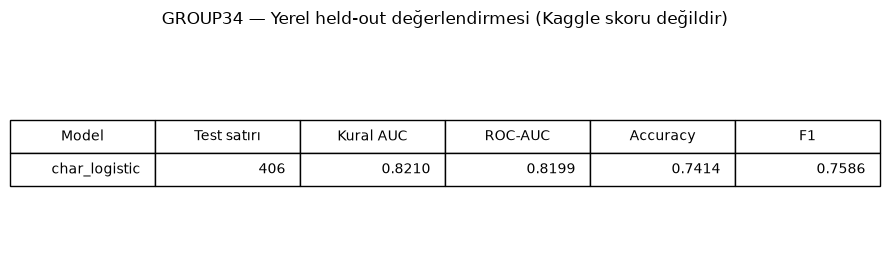

In [10]:
model = build_models()[selected]
model.fit(make_text(development), development.rule_violation)
probabilities = model.predict_proba(make_text(heldout))[:,1]
metrics, per_rule = evaluate_model(heldout, probabilities)
display(pd.DataFrame([metrics]).round(4))
display(per_rule.round(4))
per_rule.to_csv('submissions/heldout_per_rule.csv',index=False)
pd.DataFrame([dict(model=selected, seed=42, development_rows=len(development),
                   heldout_rows=len(heldout), removed_overlap=removed, **metrics)]).to_csv(
                       'submissions/heldout_metrics.csv',index=False)
fig,ax=plt.subplots(figsize=(9,2.8))
ax.axis('off')
ax.set_title('GROUP34 — Yerel held-out değerlendirmesi (Kaggle skoru değildir)',pad=16)
table=ax.table(cellText=[[selected, str(len(heldout)), f"{metrics['mean_rule_auc']:.4f}",
                        f"{metrics['roc_auc']:.4f}", f"{metrics['accuracy']:.4f}", f"{metrics['f1']:.4f}"]],
               colLabels=['Model','Test satırı','Kural AUC','ROC-AUC','Accuracy','F1'],loc='center')
table.auto_set_font_size(False);table.set_fontsize(10);table.scale(1,2)
fig.tight_layout();fig.savefig('submissions/heldout_score.png',dpi=160,bbox_inches='tight')
plt.show()


### Kamuya açık sonuçla bağlamsal karşılaştırma
[5. sıra çözüm raporu](https://www.kaggle.com/competitions/jigsaw-agile-community-rules/writeups/5th-place-solution-diverse-ensemble), tek bir LLaMA-3.1 8B bileşeni için **public LB 0.92084**, private LB 0.92618 bildirir. Bunlar o ekibin raporladığı bileşen skorlarıdır; 1. sıra veya nihai ensemble skoru olarak sunulmaz. Birinci sıradaki çözümün kendi raporuyla karşılaştırma aşağıda ayrıca verilmiştir. Kaynaktaki notebook veya kod hücreleri kullanılmadı; yalnızca yayınlanan skor kıyaslandı. Farklı veri bölmeleri nedeniyle bu kıyas aynı testte üstünlük iddiası değildir.

In [11]:
reference = 0.92084
gap = reference - metrics['mean_rule_auc']
display(Markdown(f"Yerel held-out kural AUC değerimiz **{metrics['mean_rule_auc']:.4f}**; raporda verilen public skorla aradaki sayısal fark **{gap:.4f}** AUC puanıdır. Farklı değerlendirme verileri nedeniyle doğrudan performans farkı olarak yorumlanamaz."))


Yerel held-out kural AUC değerimiz **0.8210**; raporda verilen public skorla aradaki sayısal fark **0.0999** AUC puanıdır. Farklı değerlendirme verileri nedeniyle doğrudan performans farkı olarak yorumlanamaz.

### Birinci sıradaki çözümle karşılaştırma
[Guanshuo Xu'nun 1. sıra çözüm raporu](https://www.kaggle.com/competitions/jigsaw-agile-community-rules/writeups/1st-place-solution) final ensemble için **public LB 0.9344**, **private LB 0.9293** bildirir. Bizim yerel held-out kural AUC değerimiz **0.8210**; public skorla sayısal fark **0.1134** puandır. Bu birincinin kendi raporundaki yuvarlatılmış sonuçtur; farklı test verileri nedeniyle birebir kıyas değildir. Yukarıdaki 5. sıra raporu da ikinci bir kamuya açık bağlamsal referanstır. Her iki kaynaktan yalnızca raporlanan skorlar alınmış, notebook/kod hücreleri kullanılmamıştır.

### Örnek test için tahmin dosyası
Etiketsiz örnek test için son model bütün etiketli veri üzerinde eğitilir. Bu eğitim held-out raporu kaydedildikten sonra yapılır; bu son modelin bağımsız test skoru yoktur. Yarışma kod yarışmasıdır; yerelde CSV üretmek resmi Kaggle gönderimi sayılmaz.

In [12]:
final_model = build_models()[selected]
final_model.fit(make_text(train), train.rule_violation)
submission = pd.DataFrame({'row_id':test.row_id,
                          'rule_violation':final_model.predict_proba(make_text(test))[:,1]})
sample = pd.read_csv('data/sample_submission.csv')
assert submission.row_id.equals(sample.row_id)
assert submission.rule_violation.between(0,1).all()
Path('outputs').mkdir(exist_ok=True)
submission.to_csv('outputs/submission.csv',index=False)
print('Tahmin dosyası üretildi. Satır sayısı:',len(submission))
print('Resmi Kaggle gönderimi yapılmadı.')

Tahmin dosyası üretildi. Satır sayısı: 10
Resmi Kaggle gönderimi yapılmadı.


## 7. Sonuç ve sonraki adımlar
Geliştirme bölümünde karşılaştırılan üç basit modelden biri kural AUC'sine göre seçildi; ayrı held-out skoru yukarıda kaydedildi. Yorum gruplarının ayrılması veri sızıntısı riskini azaltır. Veri yalnızca iki kural içerdiğinden yeni kurallara genelleme sonucu çıkarılamaz. Örnek testte yalnızca 10 satır bulunması tam gizli test başarısını ölçmeye yetmez.

Sonraki adımlar: örnek yorumların etkisini yalnızca geliştirme bölümünde incelemek, daha güçlü metin temsillerini karşılaştırmak ve kural/topluluk dışında genellemeyi ayrıca ölçmek. Sonuçlar insan moderasyon kararlarının yerine doğrudan kullanılmamalı; yanlış pozitiflerin etkisi dikkate alınmalıdır.

**Kaynaklar:** [Ders yönergesi](https://github.com/ceng313-2026), [yarışma ve metrik](https://www.kaggle.com/competitions/jigsaw-agile-community-rules/overview/abstract), [skor karşılaştırması](https://www.kaggle.com/competitions/jigsaw-agile-community-rules/writeups/5th-place-solution-diverse-ensemble).
